:::{admonition} Download
:class: important

Download this notebook: **{nb-download}`efgp.ipynb`**!

:::


# Gaussian Process Regression in NeMoS!

**Gaussian Processes** (GPs) [$^{[1]}$](#ref-1) are a powerful model class used in neuroscience to describe low-dimensional tuning curves and neural trajectories.
However, they have been historically difficult to fit to large-scale datasets due to the poor scaling behavior of traditional fitting approaches.
In this notebook, we illustrate how NeMoS leverages recent advances in the GP literature to enable *rapid and accurate* inference of the GP predictive mean for neural data.

In [1]:
import jax
jax.config.update('jax_enable_x64', True)

import jax.numpy as jnp
import jax.random as jr
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

import nemos as nmo
from nemos.basis import FourierGP

## when do you want to use a GP?
Let's say we measure a neuron's firing rate across many stimulus presentations with varying stimulus strength.
Our goal is to learn this neuron's **tuning curve**: a function which defines the neural firing rate in response to any stimulus strength.
In this example, we've defined the ground truth tuning curve as a cubic function of the stimulus value and generated synthetic measurements corrupted by Gaussian noise.

In [2]:
def evaluate_tuning(stimulus):
    return 0.2 * (stimulus ** 3) - 2.5 * (stimulus ** 2) + 6 * stimulus

def generate_observations(key, n_obs, stim_min, stim_max, noise_sigma):
    stimulus_key, subkey = jr.split(key)
    obs_stimuli = jr.uniform(
        stimulus_key,
        shape = (n_obs,),
        minval = stim_min,
        maxval = stim_max
    )
    true_firing_rate = evaluate_tuning(obs_stimuli)
    firing_rate_key, subkey = jr.split(subkey)
    firing_rate_noise = jr.normal(firing_rate_key, shape = (n_obs,)) * noise_sigma
    obs_firing_rate = true_firing_rate + firing_rate_noise
    return obs_stimuli, obs_firing_rate, true_firing_rate

key = jr.key(seed = 0)
n_obs = 100
stim_min = 0
stim_max = 10
noise_sigma = 1
observations = generate_observations(key, n_obs, stim_min, stim_max, noise_sigma)
obs_stimuli, obs_firing_rate, true_firing_rate = observations

n_pred = 300
pred_stimuli = jnp.linspace(stim_min, stim_max, n_pred)

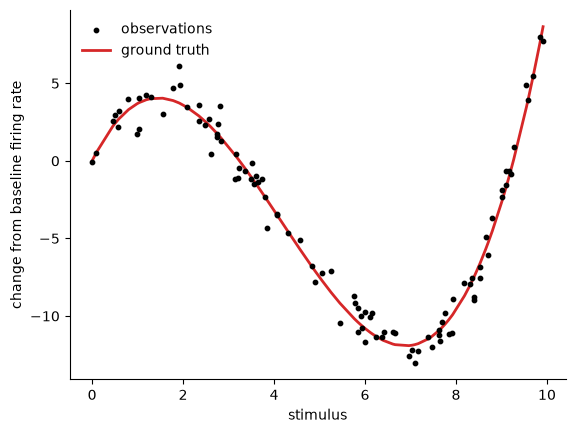

In [3]:
fig, axes = plt.subplots(1, 1)
axes.scatter(
    obs_stimuli,
    obs_firing_rate,
    s = 10,
    c = 'k',
    label = 'observations',
    zorder = 5
)

sorted_indices = jnp.argsort(obs_stimuli)
axes.plot(
    obs_stimuli[sorted_indices],
    true_firing_rate[sorted_indices],
    lw = 2,
    c = 'tab:red',
    label = 'ground truth'
)
axes.set_xlabel('stimulus')
axes.set_ylabel('change from baseline firing rate')
axes.legend(frameon = False)

## how does a GP work?

A GP makes a prediction for the *distribution* of functions that are compatible with our prior beliefs as well as the observed data.
Here, we'll just focus on the GP's **predictive mean**, or the average of the GP's predicted distribution of functions.
Critically, our prior beliefs determine what types of functions are reasonable predictions, and these prior beliefs are entirely specified by choosing a **kernel**.


The kernel tells us how similar two points in the function should be.
A standard choice of kernel is the **squared exponential** kernel, which enforces that nearby points should be more similar to each other than dispersed points.
In other words, the squared exponential kernel is a way to specify our prior beliefs that the function is *smooth*.
The **length scale** parameter determines the degree of smoothness we expect in our functions - a larger length scale implies a *slower* drop-off in covariance between more distant points, meaning the function must be smoother.

In [4]:
length_scale = 0.7
output_scale = 1
def se_kernel(
    stim_1,
    stim_2=jnp.array([0]),
    length_scale=length_scale,
    output_scale=output_scale
):
    diff = stim_1[:, None] - stim_2[None, :]
    return output_scale * jnp.exp(-0.5 * diff**2 / length_scale**2)

# odd count so the symmetric grid contains an exact 0 at index n_test_stimuli // 2;
# the kernel-approximation cell uses that as the zero-difference reference point.
n_test_stimuli = 101
test_stimuli_diffs = jnp.linspace(-0.5*stim_max, 0.5*stim_max, n_test_stimuli)
kernel_evals = se_kernel(test_stimuli_diffs)
smaller_length_scale_evals = se_kernel(test_stimuli_diffs, length_scale = 0.4)
larger_length_scale_evals = se_kernel(test_stimuli_diffs, length_scale = 1.0)

Text(0, 0.5, 'covariance between stimuli')

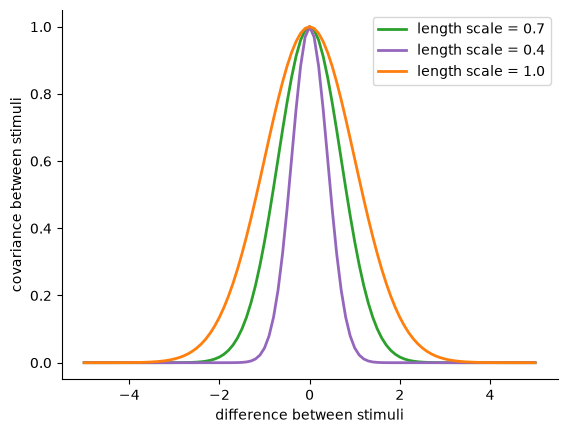

In [5]:
fig, axes = plt.subplots(1, 1)
axes.plot(
    test_stimuli_diffs,
    kernel_evals,
    lw = 2,
    c = 'tab:green',
    label = 'length scale = 0.7'
)
axes.plot(
    test_stimuli_diffs,
    smaller_length_scale_evals,
    lw = 2,
    c = 'tab:purple',
    label = 'length scale = 0.4'
)
axes.plot(
    test_stimuli_diffs,
    larger_length_scale_evals,
    lw = 2,
    c = 'tab:orange',
    label = 'length scale = 1.0'
)
axes.legend()
axes.set_xlabel('difference between stimuli')
axes.set_ylabel('covariance between stimuli')

To get more intuition about how the choice of kernel specifies a prior over functions, we can draw samples from these GPs with varying length scale!

In [6]:
n_stimuli_range = 101
stimuli_range = jnp.linspace(stim_min, stim_max, n_stimuli_range)

base_key = jr.key(seed = 123)
sampling_keys = jr.split(base_key, 3)
n_function_samples = 5

mean_values = jnp.zeros(n_stimuli_range)
jitter = 1e-6 * jnp.eye(n_stimuli_range)

K_medium = se_kernel(stimuli_range, stimuli_range) + jitter
samples_medium = jr.multivariate_normal(
    sampling_keys[0],
    mean_values,
    K_medium,
    shape = (n_function_samples, )
)

K_small = se_kernel(stimuli_range, stimuli_range, length_scale = 0.4) + jitter
samples_small = jr.multivariate_normal(
    sampling_keys[1],
    mean_values,
    K_small,
    shape = (n_function_samples, )
)

K_large = se_kernel(stimuli_range, stimuli_range, length_scale = 1.0) + jitter
samples_large = jr.multivariate_normal(
    sampling_keys[2],
    mean_values,
    K_large,
    shape = (n_function_samples, )
)

Text(0.5, 0, 'stimulus')

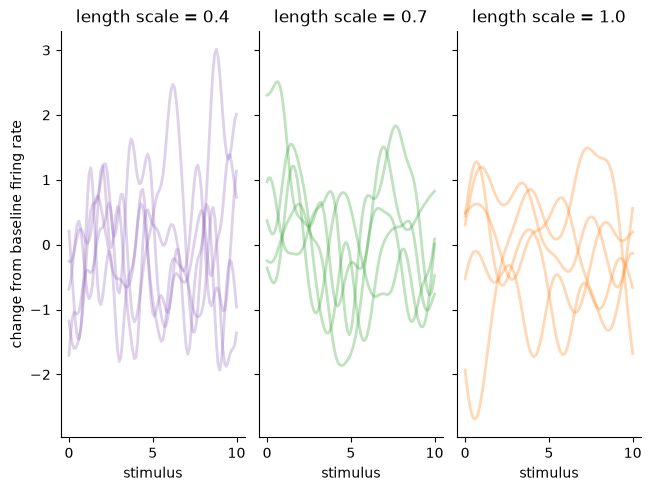

In [7]:
fig, axes = plt.subplots(1, 3, sharex = True, sharey = True, layout = 'constrained')
axes[0].plot(
    stimuli_range,
    samples_small.T,
    lw = 2,
    c = 'tab:purple',
    alpha = 0.3
)
axes[0].set_title('length scale = 0.4')
axes[0].set_xlabel('stimulus')
axes[0].set_ylabel('change from baseline firing rate')

axes[1].plot(
    stimuli_range,
    samples_medium.T,
    lw = 2,
    c = 'tab:green',
    alpha = 0.3
)
axes[1].set_title('length scale = 0.7')
axes[1].set_xlabel('stimulus')

axes[2].plot(
    stimuli_range,
    samples_large.T,
    lw = 2,
    c = 'tab:orange',
    alpha = 0.3
)
axes[2].set_title('length scale = 1.0')
axes[2].set_xlabel('stimulus')

Once we specify our prior beliefs by choosing a kernel, finding the predictive mean of the GP is remarkably simple!
When we try it out on the synthetic dataset from above, we can see that the GP is doing a fairly good job at capturing the relationship between the stimulus strength and the neural firing rate.

In [8]:
def compute_predictive_mean(
    pred_stimuli,
    obs_stimuli,
    obs_firing_rate,
    noise_sigma
):
    n_obs = obs_stimuli.shape[0]
    noise_matrix = (noise_sigma**2) * jnp.eye(n_obs)
    K_obs  = se_kernel(obs_stimuli, obs_stimuli) + noise_matrix
    K_cross = se_kernel(pred_stimuli, obs_stimuli)
    cfac = jax.scipy.linalg.cho_factor(K_obs)
    w = jax.scipy.linalg.cho_solve(cfac, obs_firing_rate)
    mu_pred = K_cross @ w
    return mu_pred

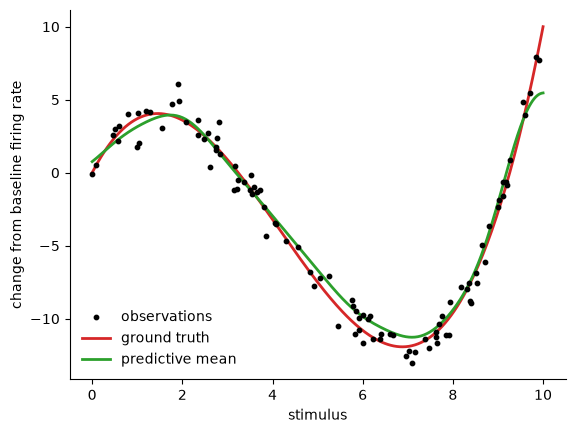

In [9]:
fig, axes = plt.subplots(1, 1)
axes.scatter(
    obs_stimuli,
    obs_firing_rate,
    s = 10,
    c = 'k',
    label = 'observations',
    zorder = 5
)
axes.plot(
    pred_stimuli,
    evaluate_tuning(pred_stimuli),
    lw = 2,
    c = 'tab:red',
    label = 'ground truth'
)

mu_pred = compute_predictive_mean(
    pred_stimuli,
    obs_stimuli,
    obs_firing_rate,
    noise_sigma
)
axes.plot(
    pred_stimuli,
    mu_pred,
    color = 'tab:green',
    lw = 2,
    label = 'predictive mean'
)
axes.set_xlabel('stimulus')
axes.set_ylabel('change from baseline firing rate')
axes.legend(frameon = False)

In [10]:
# save image for thumbnail
from pathlib import Path
import os

root = os.environ.get("READTHEDOCS_OUTPUT")
if root:
   path = Path(root) / "html/_static/thumbnails/background"
# if local store in ../_build/html/...
else:
   path = Path("../_build/html/_static/thumbnails/background")

# make sure the folder exists if run from build
if root or Path("../assets/stylesheets").exists():
   path.mkdir(parents=True, exist_ok=True)

if path.exists():
  fig.savefig(path / "plot_gp_regression.svg")

## what's the problem?

Although computing the predictive mean is quite simple, it requires inverting an $n \times n$ matrix, where $n$ is the number of observations.
This is an $\mathcal{O}(n^3)$ operation, which becomes prohibitive for increasingly large neuroscientific datasets.

:::{attention}
For timing comparisons in this notebook, we will use the ability to compile functions ahead-of-time in `jax`.
This allows us to compare the pure runtime of GP inference approaches without timing artifacts due to compilation time.
In real-world uses, the compilation time is typically negligible relative to the inference time, especially as datasets get larger.
:::

In [11]:
import time

def compile(func, *args, **kwargs):
    """Compile ``func`` ahead of time for the shapes of the given arguments.

    ``jax.jit`` compiles on the first call, so timing that call would include tracing
    """
    return jax.jit(func).trace(*args, **kwargs).lower().compile()

dataset_sizes = jnp.logspace(2, 4, num = 9, dtype = int)
times = []
for (i, size) in enumerate(dataset_sizes):
    key = jr.key(seed = i)
    observations = generate_observations(
        key,
        size,
        stim_min,
        stim_max,
        noise_sigma
    )
    stimuli, firing_rate, true_firing_rate = observations
    compiled = compile(
        compute_predictive_mean,
        pred_stimuli,
        stimuli,
        firing_rate,
        noise_sigma
    )
    start_time = time.perf_counter()
    mu_pred = compiled(
        pred_stimuli,
        stimuli,
        firing_rate,
        noise_sigma
    ).block_until_ready()
    inference_time = time.perf_counter() - start_time
    times.append(inference_time)
times = jnp.array(times)

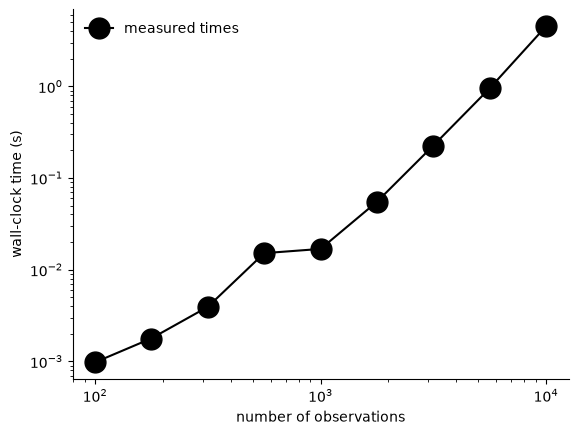

In [12]:
fig, axes = plt.subplots(1, 1, sharex = True)
axes.plot(
    dataset_sizes,
    times,
    marker = '.',
    ms = 30,
    c = 'k',
    label = 'measured times'
)
axes.set_yscale('log')
axes.set_xscale('log')
axes.set_ylabel('wall-clock time (s)')
axes.set_xlabel('number of observations')
axes.legend(frameon = False)

## what do we do?

Increasing the efficiency of GP regression has been a research topic for several years.
**Equispaced Fourier Gaussian Processes** (EFGP) is a recently developed fast algorithm for GP regression which leverages a basis function approximation to eliminate the $\mathcal{O}(n^3)$ matrix inversion required for standard GP regression [$^{[2]}$](#ref-2).
By using $m \ll n$ basis functions, this leads to dramatic improvements in inference time.
Critically, this algorithm *guarantees* approximation of the kernel to a user-specified tolerance!

:::{attention}
As the user-specified tolerance (`eps`) decreases towards 0, the kernel approximation gets better.
However, this also inflates the number of basis functions $m$ used for inference and mitigates the efficiency of EFGP.
Extremely small values for `eps` should therefore be avoided whenever possible.
:::

In [13]:
bounds = (stim_min, stim_max)
eps = 1e-4

basis = FourierGP(
    lengthscale=length_scale,
    bounds=bounds,
    eps=eps,
    variance=output_scale
)

Phi = basis.evaluate(test_stimuli_diffs)
K_pred_approx = Phi @ Phi.T
half_index = test_stimuli_diffs.shape[0] // 2
approx_kernel = K_pred_approx[half_index]

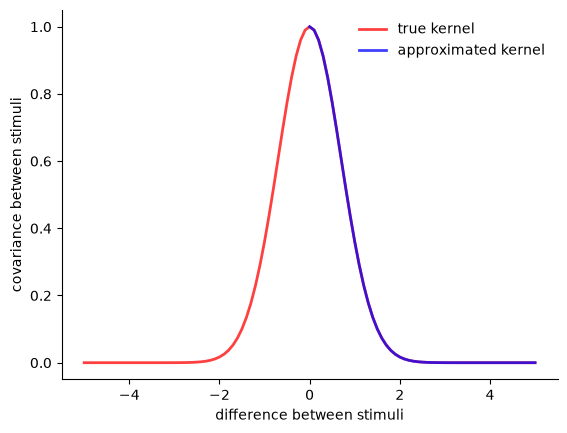

In [14]:
fig, axes = plt.subplots(1, 1)
axes.plot(
    test_stimuli_diffs,
    kernel_evals,
    lw = 2,
    c = 'r',
    label = 'true kernel',
    alpha = 0.75
)
axes.plot(
    test_stimuli_diffs,
    approx_kernel,
    lw = 2,
    c = 'b',
    label = 'approximated kernel',
    alpha = 0.75
)
axes.set_xlabel('difference between stimuli')
axes.set_ylabel('covariance between stimuli')
axes.legend(frameon = False)

With such a high-quality approximation to the kernel, the EFGP approximate predictions are practically indistinguishable from the exact GP prediction.

In [15]:
def compute_efgp_mean(
    pred_eval,
    obs_eval,
    obs_firing_rate,
    noise_sigma
):
    n_weights = obs_eval.shape[1]
    noise_matrix = (noise_sigma**2) * jnp.eye(n_weights)
    augmented_K_obs = (obs_eval.T @ obs_eval) + noise_matrix
    cfac = jax.scipy.linalg.cho_factor(augmented_K_obs)
    beta = jax.scipy.linalg.cho_solve(cfac, obs_eval.T @ obs_firing_rate)
    w = (obs_firing_rate - obs_eval @ beta) / (noise_sigma ** 2)
    K_cross = pred_eval @ obs_eval.T
    mu_pred = K_cross @ w
    return mu_pred

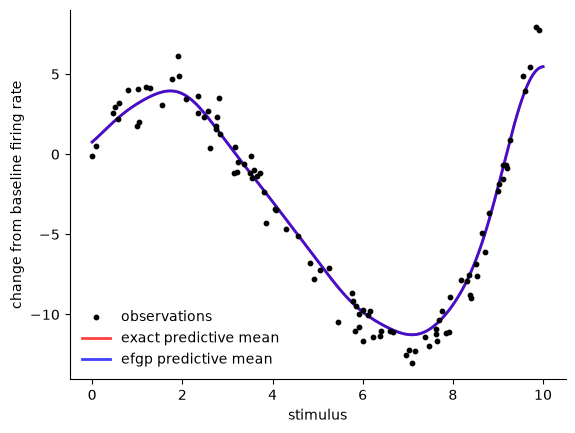

In [16]:
fig, axes = plt.subplots(1, 1)
axes.scatter(
    obs_stimuli,
    obs_firing_rate,
    s = 10,
    c = 'k',
    label = 'observations',
    zorder = 5
)

mu_pred = compute_predictive_mean(
    pred_stimuli,
    obs_stimuli,
    obs_firing_rate,
    noise_sigma
)
axes.plot(
    pred_stimuli,
    mu_pred,
    color = 'r',
    lw = 2,
    label = 'exact predictive mean',
    alpha = 0.75
)

pred_eval = basis.evaluate(pred_stimuli)
obs_eval = basis.evaluate(obs_stimuli)
approx_mu_pred = compute_efgp_mean(
    pred_eval,
    obs_eval,
    obs_firing_rate,
    noise_sigma
)
axes.plot(
    pred_stimuli,
    approx_mu_pred,
    color = 'b',
    lw = 2,
    label = 'efgp predictive mean',
    alpha = 0.75
)
axes.set_xlabel('stimulus')
axes.set_ylabel('change from baseline firing rate')
axes.legend(frameon = False)

However, we are able to achieve such high-quality predictions much more efficiently due to the use of a small set of basis functions!

In [17]:
dataset_sizes = jnp.logspace(2, 4, num = 9, dtype = int)
efgp_times = []
for (i, size) in enumerate(dataset_sizes):
    key = jr.key(seed = i)
    observations = generate_observations(
        key,
        size,
        stim_min,
        stim_max,
        noise_sigma
    )
    stimuli, firing_rate, true_firing_rate = observations
    pred_eval = basis.evaluate(pred_stimuli)
    obs_eval = basis.evaluate(stimuli)
    compiled = compile(
        compute_efgp_mean,
        pred_eval,
        obs_eval,
        firing_rate,
        noise_sigma
    )
    start_time = time.perf_counter()
    mu_pred = compiled(
        pred_eval,
        obs_eval,
        firing_rate,
        noise_sigma
    ).block_until_ready()
    inference_time = time.perf_counter() - start_time
    efgp_times.append(inference_time)
efgp_times = jnp.array(efgp_times)

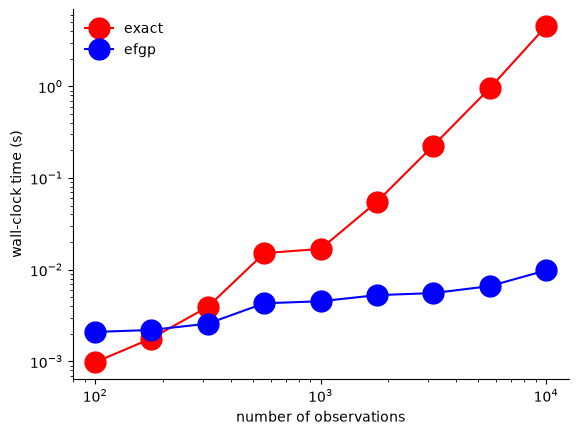

In [18]:
fig, axes = plt.subplots(1, 1, sharex = True)
axes.plot(
    dataset_sizes,
    times,
    marker = '.',
    ms = 30,
    c = 'r',
    label = 'exact'
)

axes.plot(
    dataset_sizes,
    efgp_times,
    marker = '.',
    ms = 30,
    c = 'b',
    label = 'efgp'
)

axes.set_yscale('log')
axes.set_xscale('log')
axes.set_ylabel('wall-clock time (s)')
axes.set_xlabel('number of observations')
axes.legend(frameon = False)

## References
(ref-1)=
[1] [Rasmussen C. E. and Williams C. K. I. Gaussian Processes for Machine Learning. (2006). The MIT Press](https://gaussianprocess.org/gpml/chapters/RW.pdf)
(ref-2)=
[2] [Greengard P., Rachh M. and Barnett A. Equispaced Fourier Representations for Efficient Gaussian Process Regression from a Billion Data Points. (2022). SIAM/ASA Journal on Uncertainty Quantification 13 63](https://epubs.siam.org/doi/10.1137/23M1565310)